# 78장 · HTML 입력 요소와 반응형 CSS

HTML은 입력 요소와 레이블의 관계를 나타내고 CSS는 배치를 정합니다. 마우스로 레이블을 눌렀을 때 어느 입력에 초점이 가는지 확인합니다.

투두 화면에서 ‘할 일 제목’을 눌렀는데 입력창에 커서가 가지 않습니다. HTML이 레이블과 입력칸을 어떻게 묶는지 살펴본 뒤, 노트북 안에 실제로 그린 화면에서 글자와 간격을 바꾸어 봅니다.

실행을 확인한 커널은 Python 3.12.15입니다. 예제에 사용한 외부 패키지는 ipython 9.17.1입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## label의 for와 input의 id

label의 for 값은 입력 요소의 id를 가리킵니다. placeholder는 입력하면 사라지므로 항상 읽을 수 있는 이름을 대신하지 못합니다. 아래 예제는 78장 wireframe에서 제목, 입력, 버튼만 뽑았습니다.


### 버튼을 표시하는 것과 활성화하는 것

<p>button은 화면에 보이지만 disabled 속성이 있어 누를 수 없습니다. type="button"으로 선언한 버튼에 실제 추가 동작을 연결하려면 별도의 이벤트 처리가 필요합니다.</p>


### 셀 01 · HTML 입력 요소와 버튼

노트북에서 레이블을 눌러 커서가 옮겨지는지 보세요. 정적 시안이라 버튼은 비활성입니다.


In [1]:
from IPython.display import display
markup = """<section class="todo-demo">
<label for="todo-title">할 일 제목</label>
<div class="input-row"><input id="todo-title" type="text" placeholder="예: CSS 간격 바꾸기">
<button type="button" disabled>추가 동작 준비 중</button></div></section>"""
display({"text/html": markup, "text/plain": "할 일 제목 · 입력칸 · 추가 동작 준비 중(비활성)"}, raw=True)

할 일 제목 · 입력칸 · 추가 동작 준비 중(비활성)

화면에 입력칸이 보이지만 입력 내용을 저장하는 코드는 없습니다. 표시와 저장을 따로 설계하면 화면을 읽기 전에 서버를 준비할 필요가 없습니다.


### for와 id가 같을 때의 초점 이동

<p>레이블의 for 값은 입력 요소의 id를 가리킵니다. 표시 문구가 같아도 이 두 값이 다르면 브라우저가 올바른 입력칸을 연결할 수 없습니다. 레이블 글자를 눌러 어느 입력칸에 초점이 가는지 확인하세요.</p>


### 과제 02 · label과 id 연결

for가 다른 이름을 가리키는 짧은 화면을 고쳐 레이블로 입력칸에 초점을 보낼 수 있게 하세요.


In [2]:
broken = '<label for="task-a">새 제목</label><input id="task-b">'
# for의 값을 task-b로 변경하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>broken = &#x27;&lt;label for=&quot;task-a&quot;&gt;새 제목&lt;/label&gt;&lt;input id=&quot;task-b&quot;&gt;&#x27;
fixed = broken.replace(&#x27;for=&quot;task-a&quot;&#x27;, &#x27;for=&quot;task-b&quot;&#x27;)
display({&#x27;text/html&#x27;: fixed, &#x27;text/plain&#x27;: fixed}, raw=True)</code></pre>
<p>실행 결과</p><pre><code>&lt;label for=&quot;task-b&quot;&gt;새 제목&lt;/label&gt;&lt;input id=&quot;task-b&quot;&gt;</code></pre>
<p>for와 id가 task-b로 일치합니다. 포커스가 입력칸에 가는지 레이블을 눌러 확인하세요.</p>
</details>


### 레이블에서 실제 입력칸을 찾는 경로

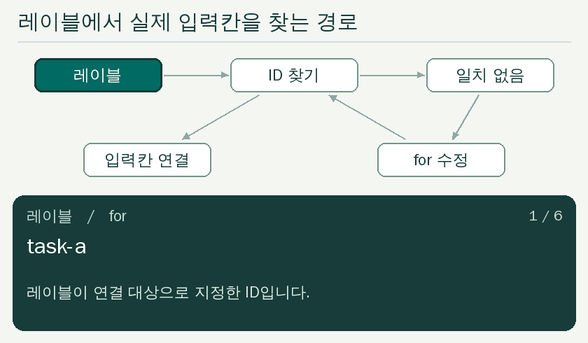

새 제목 레이블의 for를 수정하면 브라우저가 가리킬 입력칸이 달라집니다.


## 좁은 화면에서의 CSS 줄바꿈

flex 컨테이너의 gap은 자식 사이 간격입니다. wrap을 켜면 폭이 부족할 때 버튼이 다음 줄로 내려갈 수 있습니다. 입력칸 자체의 여백만 늘리면 두 요소 사이의 간격은 의도와 다를 수 있습니다.

<!-- lesson-visual practice-space -->
**폭을 줄이면 버튼이 언제 다음 줄로 내려갈까요?**

입력칸 180px, 버튼 100px, gap 10px로 고정한 flex-wrap 비교 예시입니다. 컨테이너 폭을 290px와 289px로 바꿔 보세요.

290px에서는 입력칸과 버튼이 한 줄입니다. 289px에서는 1px가 부족해 버튼이 다음 줄로 넘어갑니다.

[웹 교재에서 직접 조작하기](https://langchain-lecture.vercel.app/chapter78/#practice-space)
<!-- /lesson-visual practice-space -->


### 부모 행에 적용되는 flex와 gap

<p>display:flex와 flex-wrap:wrap은 input과 button이 함께 들어 있는 .input-row에 적용합니다. gap:10px은 두 요소 사이의 여백입니다. 입력칸 자체에 적용하면 이 둘을 한 행으로 배치할 수 없습니다.</p>


### 좁은 화면에서 첫 줄이 끝나는 위치

<p>입력칸과 버튼의 최소 너비에 사이 간격까지 더한 값보다 행이 좁으면 버튼이 다음 줄로 내려갑니다. 옆의 너비 조절 실험에서 처음으로 버튼이 내려가는 지점을 찾으세요.</p>


### 셀 03 · 반응형 CSS 수정

gap의 10px를 24px로 바꾸고 셀을 다시 실행해 입력칸과 버튼 사이를 보세요.

아래 gap은 입력칸과 버튼 사이의 간격입니다. 값을 바꾼 뒤 같은 셀을 다시 실행하면 화면 스타일과 텍스트 설명이 함께 바뀝니다.


In [3]:
gap_px = 10
style = """<style>.todo-demo .input-row { display:flex; flex-wrap:wrap; gap:GAPpx; }
.todo-demo label { display:block; margin-bottom:6px; }</style>""".replace("GAP", str(gap_px))
# 앞 셀의 id와 겹치지 않도록 새 화면에는 다른 id를 씁니다.
second = markup.replace("todo-title", "todo-title-layout")
display({"text/html": style + second, "text/plain": f"입력행 · flex-wrap: wrap · gap: {gap_px}px"}, raw=True)

입력행 · flex-wrap: wrap · gap: 10px

레이블 아래에 입력칸과 버튼이 한 묶음으로 그려집니다. CSS를 바꿔도 HTML에서 지정한 disabled 상태는 그대로입니다. 결과가 그림 대신 코드로 보이면 노트북에서 HTML 출력을 표시하는지 확인하세요.


## 돌아보기

입력칸의 이름, 버튼의 사용 가능 여부, 목록의 완료 표시를 차례로 가리켜 보세요. 다음 장에서는 과정 안내 질문을 전송하는 별도 사례로 입력값을 읽고 응답을 기다리는 순서를 익힙니다.
